# 02 Spills, labels and target

Explores the spill events, tests whether sensors respond to upstream spills,
checks how sensitive the labels are to their settings, and describes the model
target `target_6h`.

Inputs: `data/processed/` from `python -m triton.build`.
Figures are saved to `reports/figures/`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from triton.config import DATA, PROCESSED, STATIONS, TIDEWAY_DATE
from triton.io import load
from triton.labels import spill_window

FIGURES = DATA.parent / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
FAULT = "#e34948"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e6e6e3",
        "grid.linewidth": 0.6,
        "axes.edgecolor": "#8a8984",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "lines.linewidth": 1,
    }
)
NAMES = {sid: f"{sid} {cfg['name']}" for sid, cfg in STATIONS.items()}
# One fixed colour per station across every figure.
COLOUR = dict(zip(STATIONS, COLOURS, strict=True))


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")


dataset = load("dataset")
labels = load("labels")
spills = load("spills")
meta = json.loads((PROCESSED / "stations.json").read_text())


def station_events(sid):
    # Same rule as triton.spatial.station_spills, using the saved upstream lists.
    s = spills[spills["outfall"].isin(meta[sid]["upstream_outfalls"])]
    via_tunnel = s["river"].fillna("").str.contains("Tideway tunnel", case=False)
    return s[~(via_tunnel & (s["start"] >= TIDEWAY_DATE))]


events = {sid: station_events(sid) for sid in STATIONS}
dataset.head()

,station_id,timestamp,dissolved_oxygen_mg_l,ammonium_mg_l,conductivity_us_cm,turbidity_ntu,temperature_c,ph,rain_mm,flow_m3s,upstream_spill_active,hours_since_spill,label,target_6h
0,BREPON,2024-01-01 00:00:00+00:00,10.970,0.27575,605.50,NaN,9.1650,7.9200,0.0,195.94600,0,NaN,NaN,NaN
1,BREPON,2024-01-01 01:00:00+00:00,10.985,0.26800,602.50,NaN,9.1400,7.9175,0.0,198.65375,0,NaN,NaN,NaN
2,BREPON,2024-01-01 02:00:00+00:00,11.020,0.25575,597.50,NaN,9.0775,7.9325,0.0,203.33725,0,NaN,NaN,NaN
3,BREPON,2024-01-01 03:00:00+00:00,11.025,0.24525,594.25,NaN,9.0100,7.9525,0.0,202.94950,0,NaN,NaN,NaN
4,BREPON,2024-01-01 04:00:00+00:00,10.985,0.23275,590.25,NaN,8.9525,7.9600,0.0,194.89550,0,NaN,NaN,NaN


## 1. Spill events

In [2]:
print(spills.groupby([spills["start"].dt.year, "source"]).size().to_string())
summary = pd.DataFrame(
    {
        sid: {
            "upstream_outfalls": len(meta[sid]["upstream_outfalls"]),
            "events": len(e),
            "median_duration_h": round(
                ((e["end"] - e["start"]) / pd.Timedelta("1h")).median(), 1
            ),
            "share_of_hours_spilling": round(
                dataset.loc[
                    dataset["station_id"] == sid, "upstream_spill_active"
                ].mean(),
                3,
            ),
        }
        for sid, e in events.items()
    }
).T
summary

start  source          
2024   EA EDM              31623
2025   EA EDM              12133
2026   Thames Water API    12803


,upstream_outfalls,events,median_duration_h,share_of_hours_spilling
E01336A,7.0,340.0,1.4,0.033
E26020A,7.0,340.0,1.4,0.033
HAMME2,28.0,974.0,1.3,0.074
BREPON,16.0,759.0,1.3,0.076


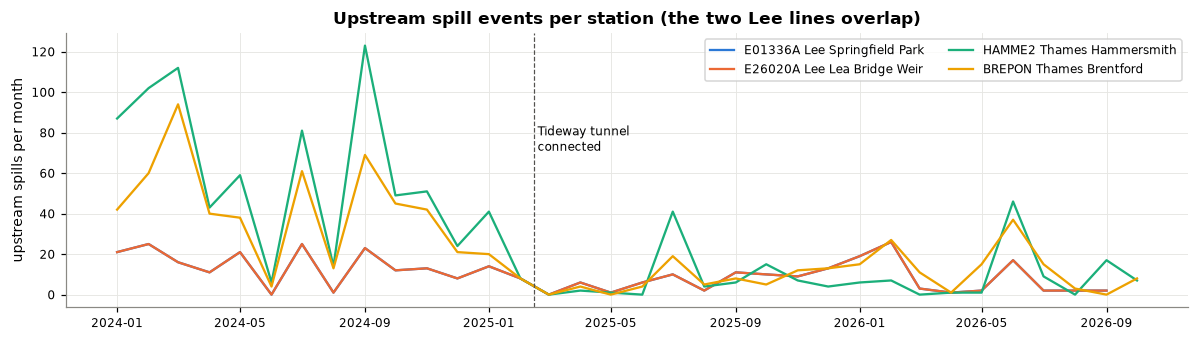

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for sid, e in events.items():
    monthly = e.set_index("start").resample("MS").size()
    ax.plot(monthly.index, monthly, color=COLOUR[sid], linewidth=1.5, label=NAMES[sid])
ax.axvline(TIDEWAY_DATE, color="#52514e", linestyle="--", linewidth=0.8)
ax.text(
    TIDEWAY_DATE, ax.get_ylim()[1] * 0.55, " Tideway tunnel\n connected", fontsize=8
)
ax.set_ylabel("upstream spills per month")
ax.set_title("Upstream spill events per station (the two Lee lines overlap)")
ax.legend(fontsize=8, ncol=2, loc="upper right")
save(fig, "02_spills_per_month")

- 56,559 spill events in total: 2024 and 2025 from the EA files, 2026 from the
  Thames Water API.
- The two Lee stations share the same 7 upstream outfalls, so their lines overlap.
- Spills are short (median 1.3 to 1.4 hours) but frequent: an upstream outfall is
  spilling in 3% of hours on the Lee and 7 to 8% on the Thames.
- Spills fall sharply from 2025. Part of this is weather (2024 was very wet, 2025
  dry), and part is the Tideway tunnel: from 14 Feb 2025, outfalls that discharge
  into the tunnel no longer count as river spills. **The years are not alike**,
  which matters for how the data is split for modelling (section 5).

## 2. Rain drives spills

station_id,BREPON,E01336A,E26020A,HAMME2
rain_band,,,,
"[0.0, 0.2)",0.013,0.002,0.002,0.015
"[0.2, 2.0)",0.076,0.003,0.003,0.062
"[2.0, 5.0)",0.269,0.037,0.037,0.174
"[5.0, 10.0)",0.438,0.166,0.166,0.260
"[10.0, 20.0)",0.755,0.360,0.360,0.632
"[20.0, inf)",1.000,0.442,0.442,0.926


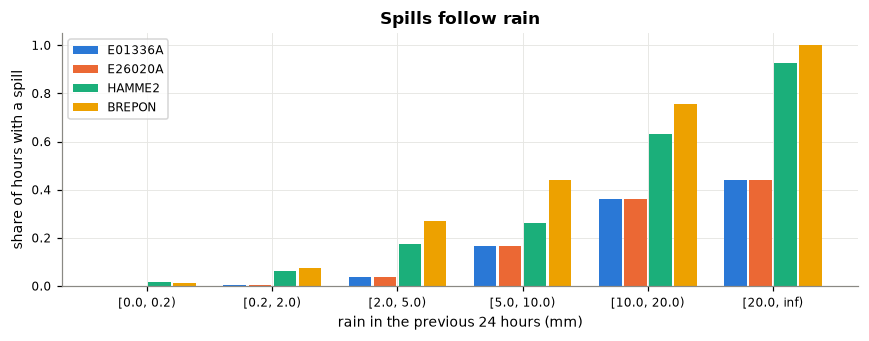

In [4]:
d = dataset.sort_values(["station_id", "timestamp"]).copy()
d["rain_24h"] = d.groupby("station_id")["rain_mm"].transform(
    lambda s: s.rolling(24, min_periods=1).sum()
)
bins = [0, 0.2, 2, 5, 10, 20, np.inf]
d["rain_band"] = pd.cut(d["rain_24h"], bins, right=False)
spill_by_rain = (
    d.groupby(["rain_band", "station_id"], observed=True)["upstream_spill_active"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(spill_by_rain))
width = 0.2
for i, sid in enumerate(STATIONS):
    ax.bar(
        x + (i - 1.5) * width,
        spill_by_rain[sid],
        width * 0.9,
        color=COLOUR[sid],
        label=sid,
    )
ax.set_xticks(x, [str(b) for b in spill_by_rain.index])
ax.set_xlabel("rain in the previous 24 hours (mm)")
ax.set_ylabel("share of hours with a spill")
ax.set_title("Spills follow rain")
ax.legend(fontsize=8)
save(fig, "02_spills_vs_rain")
spill_by_rain.round(3)

Spills are almost absent in dry weather and become the norm after heavy rain: on
the Thames, an upstream spill is active in 93 to 100% of hours after more than
20 mm of rain in 24 hours. Rain is therefore a strong early signal, available
before the spill starts, and the rolling rain totals should be model features.

## 3. Do the sensors respond to spills?

An event study: line up every upstream spill by its start time and take the median
robust z-score of ammonium and oxygen in the hours around it. Only spills starting
at least 48 hours after the previous one are used, so each window shows one event
rather than a cluster.

peak_hour       peak_z      
measure         z_do z_nh4   z_do z_nh4
station_id                             
BREPON            18     8  -0.30  0.61
E01336A            7     4  -0.87  0.65
E26020A            7     5  -0.78  0.39
HAMME2            22    15  -0.41  0.61

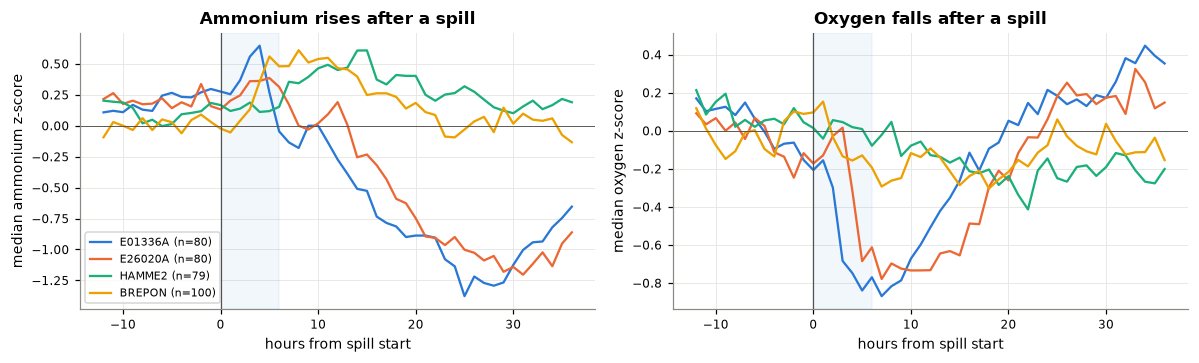

In [5]:
OFFSETS = range(-12, 37)


def isolated_starts(e, gap="48h"):
    starts = e["start"].dt.floor("1h").sort_values().drop_duplicates()
    return starts[starts.diff().isna() | (starts.diff() >= pd.Timedelta(gap))]


def event_profile(sid, column):
    z = labels[labels["station_id"] == sid].set_index("timestamp")[column]
    starts = isolated_starts(events[sid])
    windows = pd.DataFrame(
        {k: z.reindex(starts + pd.Timedelta(hours=k)).to_numpy() for k in OFFSETS}
    )
    return windows.median(), len(starts)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
peaks = []
for ax, column, label in zip(
    axes, ["z_nh4", "z_do"], ["ammonium z-score", "oxygen z-score"], strict=True
):
    for sid in STATIONS:
        profile, n = event_profile(sid, column)
        ax.plot(
            list(OFFSETS),
            profile,
            color=COLOUR[sid],
            linewidth=1.5,
            label=f"{sid} (n={n})",
        )
        after = profile.loc[0:]
        best = after.idxmax() if column == "z_nh4" else after.idxmin()
        peaks.append(
            {
                "station_id": sid,
                "measure": column,
                "peak_hour": best,
                "peak_z": round(after[best], 2),
            }
        )
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.axvspan(0, 6, color="#2a78d6", alpha=0.06)
    ax.axhline(0, color="#52514e", linewidth=0.6)
    ax.set_xlabel("hours from spill start")
    ax.set_ylabel(f"median {label}")
axes[0].set_title("Ammonium rises after a spill")
axes[1].set_title("Oxygen falls after a spill")
axes[0].legend(fontsize=7)
save(fig, "02_event_study")
pd.DataFrame(peaks).pivot(index="station_id", columns="measure")

This is the key test of the whole project: do the sensors react to upstream spills?

- **Lee: yes, clearly and quickly.** Ammonium rises within an hour of the spill
  starting and peaks after 4 hours at Springfield Park and 5 hours at Lea Bridge,
  downstream, matching the travel time found in notebook 01. Oxygen bottoms out
  about 7 hours after the start and recovers within a day. Later, ammonium drops
  below normal as the high storm flow dilutes the river.
- **Thames: slower and weaker.** Ammonium rises by a similar amount but slowly,
  peaking after 8 to 15 hours, and the oxygen drop is only about a third of the
  Lee's. A much bigger, tidal river dilutes and mixes the discharge.
- **The 6-hour window is justified for the Lee.** With spills lasting about
  1.4 hours, start to end plus 6 hours covers the ammonium peak and the start of
  the oxygen trough. For the Thames the response partly falls after the window,
  which is one reason its labels are less reliable.

## 4. How sensitive are the labels to their settings?

In [6]:
rows = []
for sid in STATIONS:
    lab = labels[labels["station_id"] == sid].set_index("timestamp")
    for after in ["3h", "6h", "12h"]:
        recent = spill_window(lab.index, events[sid], after)
        for z in [2.0, 2.5, 3.0]:
            anomaly = (lab["z_do"] < -z) | (lab["z_nh4"] > z)
            inside, outside = anomaly[recent].mean(), anomaly[~recent].mean()
            rows.append(
                {
                    "station_id": sid,
                    "window": after,
                    "z": z,
                    "label_rate_pct": round((recent & anomaly).mean() * 100, 2),
                    "anomaly_lift": round(inside / outside, 2),
                }
            )
grid = pd.DataFrame(rows)
grid.pivot_table(
    index=["station_id", "window"],
    columns="z",
    values=["anomaly_lift", "label_rate_pct"],
)

anomaly_lift             label_rate_pct            
z                          2.0   2.5   3.0            2.0   2.5   3.0
station_id window                                                    
BREPON     12h            2.40  2.79  3.22           3.52  2.68  2.13
           3h             2.82  3.34  3.90           2.53  1.98  1.62
           6h             2.66  3.17  3.68           2.96  2.31  1.86
E01336A    12h            3.47  4.29  4.21           1.33  0.97  0.74
           3h             4.24  5.33  5.78           0.87  0.65  0.54
           6h             3.88  4.93  5.17           1.04  0.78  0.63
E26020A    12h            3.83  5.00  5.87           1.84  1.39  1.04
           3h             3.86  4.91  5.60           1.01  0.77  0.58
           6h             3.82  4.98  5.86           1.31  1.01  0.77
HAMME2     12h            1.71  1.89  2.12           3.02  2.37  1.91
           3h             2.04  2.29  2.59           2.26  1.81  1.47
           6h             1.85  2.04  2.30           2.50  1.98  1.60

- **The station ranking never changes.** The Lee stations have an anomaly lift
  of 3.5 to 5.9 under every setting; Hammersmith stays lowest at 1.7 to 2.6. The
  labels reflect a real effect, not a lucky choice of settings.
- A stricter threshold raises the lift but leaves fewer positive hours to learn from.
  The chosen z = 2.5 with a 6-hour window sits in the middle of both.
- A longer window does not help the Thames: it adds more normal hours than delayed
  responses, so the lift falls.

## 5. The target: `target_6h`

In [7]:
d["year"] = d["timestamp"].dt.year
target_rates = (
    d.groupby(["station_id", "year"])["target_6h"]
    .agg(hours="count", positives="sum", rate="mean")
    .round(4)
)
target_rates

hours  positives    rate
station_id year                          
BREPON     2024   8742      549.0  0.0628
           2025   8760      261.0  0.0298
           2026   6954      263.0  0.0378
E01336A    2024   8742      179.0  0.0205
           2025   8760      122.0  0.0139
           2026   6817      119.0  0.0175
E26020A    2024   7801      181.0  0.0232
           2025   8760      151.0  0.0172
           2026   6954      134.0  0.0193
HAMME2     2024   8740      544.0  0.0622
           2025   8721      165.0  0.0189
           2026   6954      144.0  0.0207

                      since_band   
by_hours_since_spill  [0.0, 6.0)       0.3144
                      [6.0, 12.0)      0.1291
                      [12.0, 24.0)     0.0243
                      [24.0, 48.0)     0.0047
                      [48.0, 168.0)    0.0010
                      [168.0, inf)     0.0034
Name: target_6h, dtype: float64

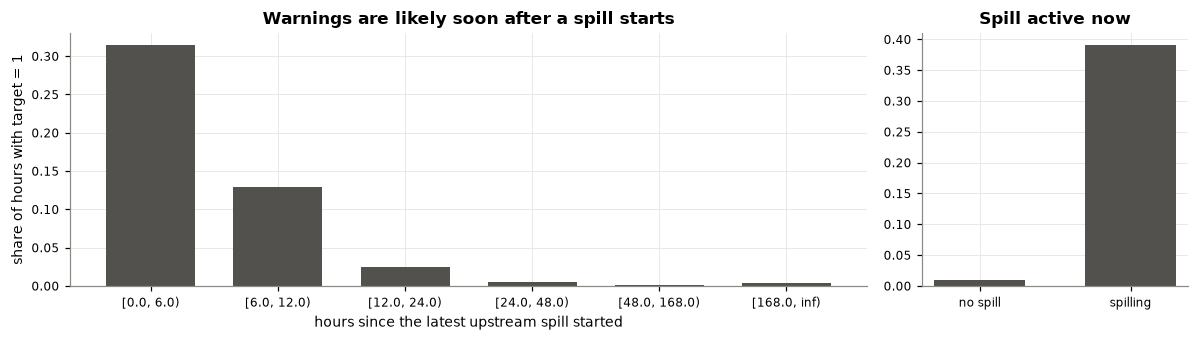

In [8]:
bins = [0, 6, 12, 24, 48, 168, np.inf]
d["since_band"] = pd.cut(d["hours_since_spill"], bins, right=False)
by_since = d.groupby("since_band", observed=True)["target_6h"].mean()
by_active = d.groupby("upstream_spill_active")["target_6h"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), width_ratios=[3, 1])
axes[0].bar(range(len(by_since)), by_since, color="#52514e", width=0.7)
axes[0].set_xticks(range(len(by_since)), [str(b) for b in by_since.index])
axes[0].set_xlabel("hours since the latest upstream spill started")
axes[0].set_ylabel("share of hours with target = 1")
axes[0].set_title("Warnings are likely soon after a spill starts")
axes[1].bar(["no spill", "spilling"], by_active, color="#52514e", width=0.6)
axes[1].set_title("Spill active now")
save(fig, "02_target_vs_spill_features")
pd.concat({"by_hours_since_spill": by_since.round(4)})

`target_6h` is 1 in about 2 to 6% of hours, depending on station and year.

- **2024 has two to three times more positives** on the Thames than 2025 and
  2026 (the wet year and the Tideway change from section 1). A model trained on 2024
  alone and tested on 2026 would face a different world. A fairer split is to train
  on 2024 and the first half of 2025, validate on the second half of 2025, and
  test on 2026.
- **Time since a spill is very predictive**, but partly by design: the label needs
  a recent spill, so the target can only be 1 shortly after one. A model that only
  learns "a spill happened" adds nothing. Its value is in telling **which** spills
  will harm the river, from the sensors and rain. The baseline below sets the bar.

In [9]:
rows = []
for sid, g in d.dropna(subset=["target_6h"]).groupby("station_id"):
    warn = g["hours_since_spill"] < 6
    hit = warn & (g["target_6h"] == 1)
    rows.append(
        {
            "station_id": sid,
            "alerts_pct_of_hours": round(warn.mean() * 100, 1),
            "precision": round(hit.sum() / warn.sum(), 3),
            "recall": round(hit.sum() / (g["target_6h"] == 1).sum(), 3),
        }
    )
baseline = pd.DataFrame(rows)
baseline

,station_id,alerts_pct_of_hours,precision,recall
0,BREPON,8.8,0.341,0.680
1,E01336A,4.6,0.277,0.740
2,E26020A,4.5,0.309,0.695
3,HAMME2,7.8,0.310,0.693


**Baseline rule:** warn whenever an upstream spill started in the last 6 hours.
It catches about 70% of events, but only about 1 alert in 3 is followed by one. A model is only useful if it beats this rule's precision at the same
recall, or its recall at the same alert rate. Report it next to every model.

## 6. Demo event: 15 February 2026

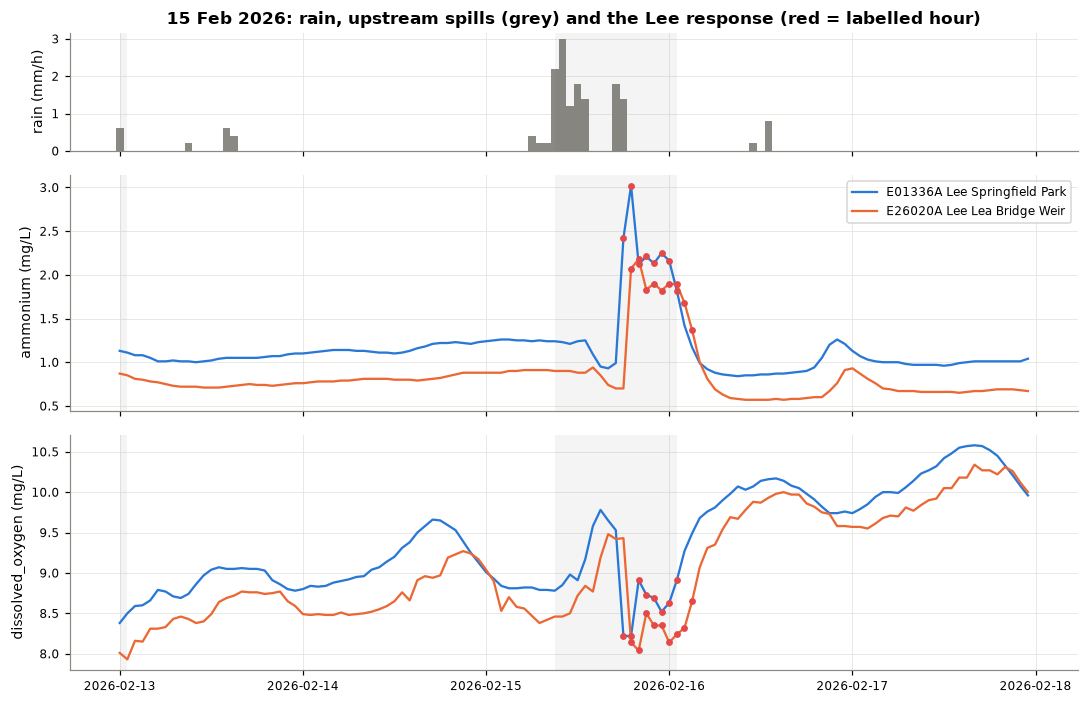

In [10]:
start = pd.Timestamp("2026-02-13", tz="UTC")
end = pd.Timestamp("2026-02-18", tz="UTC")
window = d[(d["timestamp"] >= start) & (d["timestamp"] < end)]
lee = ["E01336A", "E26020A"]

fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True, height_ratios=[1, 2, 2])
rain = window[window["station_id"] == "E01336A"]
axes[0].bar(rain["timestamp"], rain["rain_mm"], width=1 / 24, color="#8a8984")
axes[0].set_ylabel("rain (mm/h)")
for ax, column, unit in zip(
    axes[1:],
    ["ammonium_mg_l", "dissolved_oxygen_mg_l"],
    ["mg/L", "mg/L"],
    strict=True,
):
    for sid in lee:
        s = window[window["station_id"] == sid]
        ax.plot(
            s["timestamp"],
            s[column],
            color=COLOUR[sid],
            linewidth=1.5,
            label=NAMES[sid],
        )
        flagged = s[s["label"] == 1]
        ax.scatter(flagged["timestamp"], flagged[column], color=FAULT, s=12, zorder=3)
    ax.set_ylabel(f"{column.split('_mg')[0]} ({unit})")
active = window[
    (window["station_id"] == "E01336A") & (window["upstream_spill_active"] == 1)
]
for ax in axes:
    for t in active["timestamp"]:
        ax.axvspan(t, t + pd.Timedelta("1h"), color="#52514e", alpha=0.06, lw=0)
axes[1].legend(fontsize=8)
axes[0].set_title(
    "15 Feb 2026: rain, upstream spills (grey) and the Lee response "
    "(red = labelled hour)"
)
save(fig, "02_demo_event")

Rain from the early morning of 15 February sets off the upstream outfalls (grey,
from about 09:00). In the evening, after a second burst of rain, ammonium at
Springfield Park jumps from about 1 to 3 mg/L and Lea Bridge follows within the
hour, while oxygen drops by about 1.5 mg/L at both. The
labels (red) mark exactly this window. This is the scenario Triton should warn
about hours in advance, using the rain and the live spill feed.

## Findings

1. **Sensors respond to upstream spills.** On the Lee the response is clear and
   fast: ammonium peaks 4 to 5 hours after a spill starts, oxygen bottoms out
   around 7 hours. On the Thames it is slower (8 to 15 hours) and the oxygen drop
   is about a third of the Lee's.
2. **The labels are robust.** Across 9 combinations of threshold and window, the
   Lee keeps an anomaly lift of 3.5 to 5.9 and the station ranking never changes.
   The chosen settings (z = 2.5, 6-hour window) sit in the middle.
3. **Rain drives spills**, so rolling rain totals are an early signal available
   before the spill starts.
4. **The years differ.** 2024 had two to three times more Thames events than
   2025 and 2026 (wet year, then the Tideway tunnel). Split by time, with part of
   2025 in training: train 2024 to Jun 2025, validate Jul to Dec 2025, test 2026.
5. **The bar to beat:** the rule "warn if a spill started in the last 6 hours"
   catches about 70% of events with precision of about 0.3. A model must improve
   on that to be worth deploying.
6. **Expect the Lee to perform best.** Its signal is the strongest and fastest. The
   Thames needs tide-aware features, and its labels are less certain.